<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/ECMWF_Core_Logo_RGB.png" alt="ECMWF" height="44"/>

# Air quality in the Po valley, the next four days 🇮🇹
### CAMS European air quality forecast × ECMWF 9 km wind · free Copernicus key

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/italy/po_valley_air_quality.ipynb)

The Po valley is one of Europe's air-pollution hot spots: the Alps and the Apennines close it on three
sides, and in winter cold air settles on the valley floor with little wind to clear it, so fine particles (PM2.5)
from traffic, heating and farming build up. This notebook takes the latest **CAMS European air quality forecast**, run
for the European Union by ECMWF with eleven European models, finds the most polluted hour of the next four days and
maps it with the **ECMWF 9 km wind** at that hour. One line switches to nitrogen dioxide (NO₂).

**What you need:** a Google account (to use Colab) and a free Copernicus account (step below). Everything runs on
Google's computers, so a slow or mobile connection is fine.

| Data | What this notebook uses | Licence |
|---|---|---|
| [CAMS European air quality forecast](https://ads.atmosphere.copernicus.eu/datasets/cams-europe-air-quality-forecasts), ensemble median, 0.1° | PM2.5 or NO₂ at the surface, latest 00 UTC run, 3-hourly to +96 h | Copernicus licence, free |
| [ECMWF open data](https://www.ecmwf.int/en/forecasts/datasets/open-data), IFS 9 km | 10 m wind at the same hour, same run | CC BY 4.0, © ECMWF |

**Tools:** [earthkit](https://earthkit.ecmwf.int), ECMWF's free, open-source Python tools, with cartopy.

*Press **Runtime → Run all**. The Atmosphere Data Store queues requests, so step 2 can take a few minutes.*

> Not an official ECMWF product: a worked example for the ECMWF liaison visit to Italy, 2026.

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes a few minutes the first time.
%pip install -q "earthkit-data[cds,ecmwf-opendata]" earthkit-plots ecmwf-opendata

## Your free Copernicus key

Copernicus data is free and open, but the data stores ask you to register once so they can manage the queue:
1. Create an account at [cds.climate.copernicus.eu](https://cds.climate.copernicus.eu) (the same login works for the
   Atmosphere Data Store).
2. Open the [dataset page](https://ads.atmosphere.copernicus.eu/datasets/cams-europe-air-quality-forecasts?tab=download) on the Atmosphere Data Store and accept its licence (bottom of the Download tab). You only do this once.
3. Copy your API key from your [profile page](https://cds.climate.copernicus.eu/profile) and paste it below.

**Use your own key.** Everyone who runs this notebook needs their own free Copernicus account and key. The next cell asks
for it in a hidden box and saves it on the machine running the notebook (in Colab that is a temporary machine, wiped when
you close the tab). The key is never stored in the notebook, so don't paste it into a code cell, and don't share a notebook
or screenshot that shows it. On your own computer with `~/.cdsapirc` / `~/.adsapirc` already in place, the cell asks nothing.

In [2]:
import os
from getpass import getpass
rc = {"~/.cdsapirc": "https://cds.climate.copernicus.eu/api", "~/.adsapirc": "https://ads.atmosphere.copernicus.eu/api"}
missing = [p for p in rc if not os.path.exists(os.path.expanduser(p))]
if missing:
    key = getpass("Copernicus API key: ")
    for p in missing:
        with open(os.path.expanduser(p), "w") as f:
            f.write(f"url: {rc[p]}\nkey: {key}\n")
print("Copernicus key ready")

Copernicus key ready


In [3]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import datetime as dt
import numpy as np
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from ecmwf.opendata import Client

## 1 · Choose the pollutant and the area

In [4]:
POLLUTANT = "pm25"     # "pm25" (fine particles) or "no2" (nitrogen dioxide, mostly traffic)
LEAD = None             # hours after 00 UTC (0, 3 ... 96); None: the most polluted hour over the map

AREA = dict(north=47.0, south=43.0, west=6.6, east=14.0)   # the Po valley
CITIES = [("Turin", 45.07, 7.687),
          ("Milan", 45.464, 9.19),
          ("Bergamo", 45.698, 9.677),
          ("Verona", 45.438, 10.992),
          ("Bologna", 44.494, 11.343),
          ("Venice", 45.44, 12.316),
          ("Parma", 44.801, 10.328)]

SETTINGS = {   # CAMS variable, label, colour levels (µg/m³)
    "pm25": dict(ads="particulate_matter_2.5um", label="PM2.5", levels=[0, 5, 10, 15, 20, 25, 35, 50, 75, 100]),
    "no2":  dict(ads="nitrogen_dioxide", label="NO$_2$", levels=[0, 5, 10, 15, 20, 30, 40, 60, 80, 120]),
}
S = SETTINGS[POLLUTANT]

## 2 · Get the CAMS air quality forecast (Atmosphere Data Store)

In [5]:
def cams(date):
    return ekd.from_source("ads", "cams-europe-air-quality-forecasts", {
        "variable": [S["ads"]], "model": ["ensemble"], "level": ["0"], "type": ["forecast"],
        "date": [f"{date}/{date}"], "time": ["00:00"], "leadtime_hour": [str(h) for h in range(0, 97, 3)],
        "area": [AREA["north"], AREA["west"], AREA["south"], AREA["east"]], "data_format": "grib"}).to_xarray()

today = dt.date.today()
try:
    x, run = cams(today.isoformat()), today                          # today's run, published by mid-morning
except Exception as err:
    print(f"Today's run is not out yet ({type(err).__name__}): using yesterday's")
    yday = today - dt.timedelta(days=1)
    x, run = cams(yday.isoformat()), yday
run = dt.datetime(run.year, run.month, run.day)
aq = x[list(x.data_vars)[0]] * 1e9                                   # kg/m³ -> µg/m³
aq = aq.assign_coords(longitude=((aq.longitude + 180) % 360) - 180, step=list(range(0, 97, 3))).sortby("latitude")
if LEAD is None:
    LEAD = int(aq.mean(["latitude", "longitude"]).idxmax())          # the most polluted hour over the map
field = aq.sel(step=LEAD)
valid = run + dt.timedelta(hours=LEAD)
print(f"CAMS run {run:%d %B %Y} 00 UTC · mapping +{LEAD} h: {valid:%A %d %B, %H:%M} UTC")
for n, la, lo in CITIES:
    print(f"  {n:10s} {float(field.sel(latitude=la, longitude=lo, method='nearest')):5.1f} µg/m³")

CAMS run 23 November 2026 00 UTC · mapping +45 h: Tuesday 24 November, 21:00 UTC
  Turin       47.7 µg/m³
  Milan       41.1 µg/m³
  Bergamo     42.2 µg/m³
  Verona      15.4 µg/m³
  Bologna     40.1 µg/m³
  Venice      10.5 µg/m³
  Parma       31.8 µg/m³


## 3 · Get the wind at the same hour (ECMWF open data, 9 km)

In [6]:
for SOURCE in ("ecmwf", "aws", "google"):      # ECMWF first, then the cloud mirrors if it is busy
    try:
        Client(SOURCE).retrieve(date=run.date(), time=0, step=LEAD, stream="oper", type="fc", levtype="sfc",
                                param=["10u", "10v"], resol="0p1", target="wind.grib2")   # resol="0p1" = 9 km
        break
    except Exception as err:
        print(f"{SOURCE} did not answer ({type(err).__name__}), trying the next mirror")
w = ekd.from_source("file", "wind.grib2").to_xarray()
w = w.assign_coords(longitude=((w.longitude + 180) % 360) - 180).sortby("longitude").sortby("latitude")
w = w.sel(latitude=slice(AREA["south"], AREA["north"]), longitude=slice(AREA["west"], AREA["east"]))
u, v = [w[n].squeeze(drop=True) for n in w.data_vars]                # 10 m wind, east and north (m/s)
speed = np.hypot(u, v)
print(f"IFS 9 km 10 m wind at the same hour: mean {float(speed.mean()):.1f} m/s, up to {float(speed.max()):.1f} m/s")

By downloading data from the ECMWF open data dataset, you agree to the terms: Attribution 4.0 International (CC BY 4.0). Please attribute ECMWF when downloading this data.


IFS 9 km 10 m wind at the same hour: mean 2.6 m/s, up to 10.9 m/s


## 4 · Map it

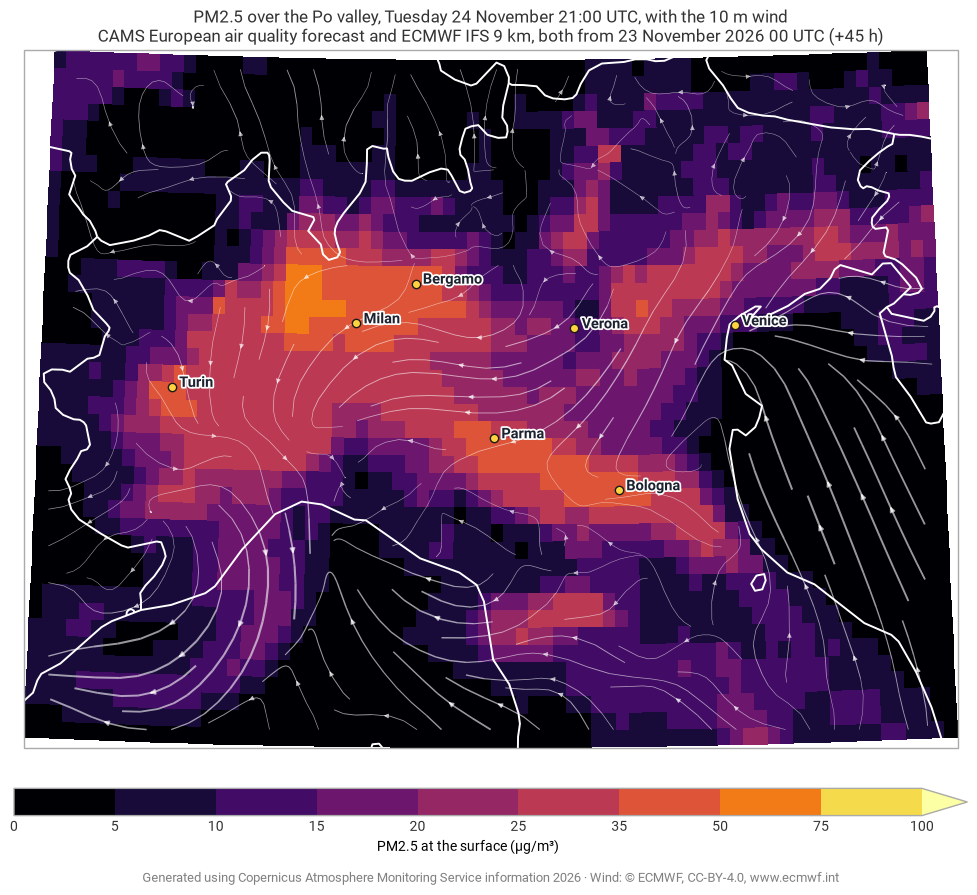

In [7]:
style = ekp.styles.Style(levels=S["levels"], colors="inferno", extend="max")
chart = ekp.Map(domain=[AREA["west"], AREA["east"], AREA["south"], AREA["north"]], figsize=(12, 8.5))
chart.pcolormesh(field, style=style)
chart.coastlines(linewidth=1.4, color="white"); chart.borders(linewidth=1.4, color="white")
# the wind as streamlines: thicker where it blows harder; light wind lets the pollution build up
chart.ax.streamplot(u.longitude.values, u.latitude.values, u.values, v.values, transform=ccrs.PlateCarree(),
                    color=(1, 1, 1, 0.6), density=1.3, arrowsize=0.7, linewidth=0.3 + 1.4 * speed.values / max(float(speed.max()), 1))
for n, la, lo in CITIES:
    chart.ax.plot(lo, la, "o", ms=6, color="#ffd23f", mec="#1a1a1a", transform=ccrs.PlateCarree(), zorder=10)
    chart.ax.text(lo, la, f"  {n}", transform=ccrs.PlateCarree(), fontsize=10.5, fontweight="bold", zorder=11,
                  color="#1d2230", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])
chart.legend(label=f"{S['label']} at the surface (µg/m³)")
chart.title(f"{S['label']} over the Po valley, {valid:%A %d %B %H:%M} UTC, with the 10 m wind\n"
            f"CAMS European air quality forecast and ECMWF IFS 9 km, both from {run:%d %B %Y} 00 UTC (+{LEAD} h)",
            fontsize=12.5)
chart.attribution("Generated using Copernicus Atmosphere Monitoring Service information 2026 · "
                  "Wind: © ECMWF, CC-BY-4.0, www.ecmwf.int")
chart.save("po_valley_air_quality.png", dpi=130)
chart.show()

## 5 · Your turn 🌍

- **Another pollutant:** set `POLLUTANT = "no2"` in step 1 (or `"pm25"`) and run all again. NO₂ follows roads and cities; PM2.5 spreads further.
- **Another hour:** set `LEAD` to any multiple of 3 from 0 to 96, for example `LEAD = 12` (midday today).
- **All of Italy:** `AREA = dict(north=47.2, south=36.5, west=6.5, east=18.6)`; add Rome `("Rome", 41.893, 12.483)` to `CITIES`.
- **Particles from the desert:** add `"dust": dict(ads="dust", label="Dust", levels=[0, 2, 5, 10, 20, 50, 100])` to `SETTINGS`.

The CAMS European forecast runs at about 10 km: it shows where pollution builds up and where the wind carries it, not
single streets. The colours are the median of the CAMS European models (the ensemble).

### Data & licence
Copernicus data is free and open under the Copernicus licence (CC-BY 4.0). Credit:
*Generated using Copernicus Atmosphere Monitoring Service information 2026.* ECMWF runs the Copernicus Atmosphere Monitoring Service and the
Copernicus Climate Change Service for the European Union.

[Climate Data Store](https://cds.climate.copernicus.eu) · [Atmosphere Data Store](https://ads.atmosphere.copernicus.eu) ·
[earthkit](https://earthkit.ecmwf.int)

**ECMWF open data**, CC BY 4.0: `© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 and ECMWF Terms of Use`.
No account, no key.